# Quinta lista de ejercicios – Selección de variables y generalización


In [81]:
import sys
from pathlib import Path

# Permite importar el paquete src/ desde notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import DIR_FIGURAS, DIR_TABLAS
from src.data import cargar_datos, particionar
from src.models import ajustar_y_evaluar, riesgo_en_prueba
from src.plots import graficar_forward
from src.selection import (
    mejor_forward, ranking_correlacion, seleccion_correlacion,
    seleccion_forward, seleccion_pruebas_t,
)

DIR_TABLAS.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

## 0. Datos y partición (`random_state=31`)

In [82]:
X, y = cargar_datos()
p = particionar(X, y)
todas = list(p.X_train.columns)
print(f"Predictoras ({len(todas)}): {todas}")
print(f"Entrenamiento: {len(p.X_train)} | Validación: {len(p.X_val)} | Prueba: {len(p.X_test)}")

Predictoras (19): ['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years', 'CAtBat', 'CHits', 'CHmRun', 'CRuns', 'CRBI', 'CWalks', 'League', 'Division', 'PutOuts', 'Assists', 'Errors', 'NewLeague']
Entrenamiento: 50 | Validación: 70 | Prueba: 143


## Ejercicio 1. Modelo completo

In [83]:
_, r1_tr, r1_val = ajustar_y_evaluar(p.X_train, p.y_train, p.X_val, p.y_val)
print(f"Riesgo entrenamiento: {r1_tr:.4f}")
print(f"Riesgo validación   : {r1_val:.4f}")

Riesgo entrenamiento: 68584.8164
Riesgo validación   : 320423.1919


## Ejercicio 2. Selección estadística de variables
### (a) Correlación con `Salary` (solo entrenamiento)

In [84]:
ranking = ranking_correlacion(p.X_train, p.y_train)
tabla_corr = ranking.rename("Correlacion").to_frame()
tabla_corr["Correlacion_abs"] = tabla_corr["Correlacion"].abs()
tabla_corr.to_csv(DIR_TABLAS / "ej2a_correlaciones.csv")
tabla_corr.round(4)

,Correlacion,Correlacion_abs
CRBI,0.4333,0.4333
CRuns,0.4252,0.4252
CHmRun,0.4181,0.4181
CHits,0.4165,0.4165
CAtBat,0.3835,0.3835
CWalks,0.2915,0.2915
Years,0.2414,0.2414
PutOuts,0.1926,0.1926
HmRun,0.1833,0.1833
RBI,0.1813,0.1813


### (b) Top 7 por correlación

In [85]:
top7 = seleccion_correlacion(p.X_train, p.y_train)
_, r2_tr, r2_val = ajustar_y_evaluar(p.X_train[top7], p.y_train, p.X_val[top7], p.y_val)
print("Variables:", top7)
print(f"Riesgo train: {r2_tr:.4f} | valid: {r2_val:.4f}")

Variables: ['CRBI', 'CRuns', 'CHmRun', 'CHits', 'CAtBat', 'CWalks', 'Years']
Riesgo train: 115487.2485 | valid: 133035.6122


### (c) Pruebas t (p < 0.05) en la regresión completa

In [86]:
vars_t = seleccion_pruebas_t(p.X_train, p.y_train)
_, r3_tr, r3_val = ajustar_y_evaluar(p.X_train[vars_t], p.y_train, p.X_val[vars_t], p.y_val)
print("Variables:", vars_t)
print(f"Riesgo train: {r3_tr:.4f} | valid: {r3_val:.4f}")

Variables: ['AtBat', 'CWalks', 'Assists']
Riesgo train: 161221.3618 | valid: 140085.1870


### (d) Comparación

In [87]:
comp2 = pd.DataFrame({
    "Modelo": ["Completo (19)", "Top 7 correlación", "Pruebas t (p<0.05)"],
    "N_variables": [len(todas), len(top7), len(vars_t)],
    "Riesgo_train": [r1_tr, r2_tr, r3_tr],
    "Riesgo_valid": [r1_val, r2_val, r3_val],
})
comp2.to_csv(DIR_TABLAS / "ej2d_comparacion.csv", index=False)
comp2.round(4)

,Modelo,N_variables,Riesgo_train,Riesgo_valid
0,Completo (19),19,68584.8164,320423.1919
1,Top 7 correlación,7,115487.2485,133035.6122
2,Pruebas t (p<0.05),3,161221.3618,140085.1870


**Análisis:** Modelo Completo (19 variables): Tiene el menor error en entrenamiento, pero el peor en validación. Al usar tantas variables para tan pocos datos, el modelo memoriza el ruido y sufre de sobreajuste 

Top 7 por Correlación: Es el más equilibrado. Reduce drásticamente el error de validación al eliminar variables redundantes

Pruebas t (p < 0.05): Es el modelo más simple. Su error de validación es muy similar al de correlación, demostrando que la mayoría de las variables originales no aportan valor estadístico real.

## Ejercicio 3. Selección hacia adelante
### (a) Tabla

In [88]:
tabla_fwd = seleccion_forward(p.X_train, p.y_train, p.X_val, p.y_val)
tabla_fwd.to_csv(DIR_TABLAS / "ej3a_forward.csv", index=False)
tabla_fwd.round(4)

,N_vars,Variable_agregada,Riesgo_train,Riesgo_valid
0,1,CRBI,144809.3173,146285.3948
1,2,Years,131715.6911,142801.7070
2,3,CRuns,126982.3235,130618.1981
3,4,AtBat,123026.4367,148610.2362
4,5,Hits,113273.7562,134668.7540
5,6,CWalks,104271.8696,162725.8921
6,7,RBI,97143.2416,196523.6458
7,8,Assists,92928.7447,188600.4397
8,9,Errors,87364.0158,211733.4913
9,10,Runs,80524.8236,271303.1315


### (b) Gráfica

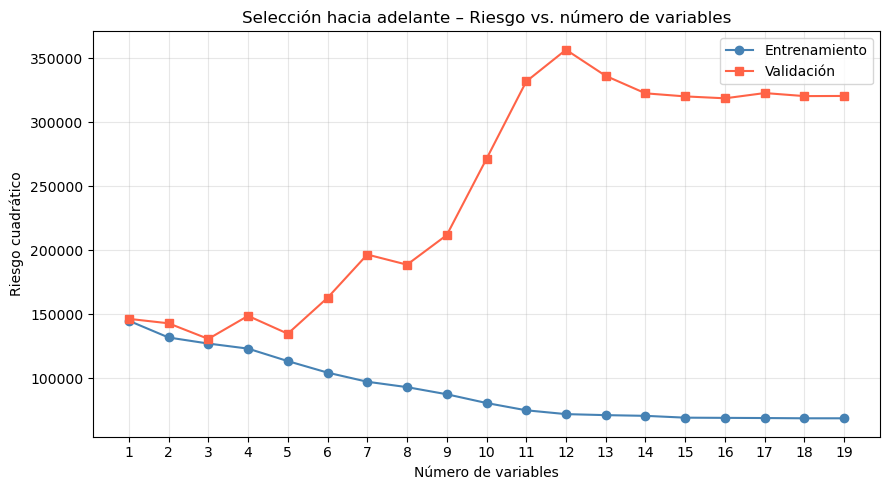

In [89]:
graficar_forward(tabla_fwd, DIR_FIGURAS / "forward_selection.png")
plt.show()

### (c) Mejor modelo por validación

In [90]:
vars_fwd, r4_tr, r4_val = mejor_forward(tabla_fwd)
print(f"{len(vars_fwd)} variables: {vars_fwd}")
print(f"Riesgo train: {r4_tr:.4f} | valid: {r4_val:.4f}")

3 variables: ['CRBI', 'Years', 'CRuns']
Riesgo train: 126982.3235 | valid: 130618.1981


## Ejercicio 4. Comparación final

In [91]:
modelos = {
    "Todas las variables": todas,
    "Mayor correlación": top7,
    "Pruebas t": vars_t,
    "Selección hacia adelante": vars_fwd,
}
r_train = [r1_tr, r2_tr, r3_tr, r4_tr]
r_val   = [r1_val, r2_val, r3_val, r4_val]
r_test  = [riesgo_en_prueba(p.X_train, p.y_train, p.X_test, p.y_test, v)
           for v in modelos.values()]
nombres = list(modelos)

i_val = min(range(4), key=r_val.__getitem__)
i_tr  = min(range(4), key=r_train.__getitem__)
i_te  = min(range(4), key=r_test.__getitem__)

# (a)
print(f"(a) Modelo elegido: {nombres[i_val]} (riesgo de validación = {r_val[i_val]:.4f})")

(a) Modelo elegido: Selección hacia adelante (riesgo de validación = 130618.1981)


In [92]:
# (b)
tabla_final = pd.DataFrame({
    "Modelo": nombres,
    "Variables": [len(v) for v in modelos.values()],
    "Riesgo_train": r_train,
    "Riesgo_valid": r_val,
    "Riesgo_prueba": r_test,
})
tabla_final.to_csv(DIR_TABLAS / "ej4b_tabla_final.csv", index=False)
tabla_final.round(4)

,Modelo,Variables,Riesgo_train,Riesgo_valid,Riesgo_prueba
0,Todas las variables,19,68584.8164,320423.1919,394308.6934
1,Mayor correlación,7,115487.2485,133035.6122,145923.2919
2,Pruebas t,3,161221.3618,140085.1870,158772.4728
3,Selección hacia adelante,3,126982.3235,130618.1981,126939.5956


In [93]:
# (c)
print(f"Menor riesgo de entrenamiento: {nombres[i_tr]} ({r_train[i_tr]:.4f})")
print(f"Menor riesgo de prueba       : {nombres[i_te]} ({r_test[i_te]:.4f})")
print("¿Coinciden?", "Sí" if i_tr == i_te else "No")

# (d)
print(f"\nElegido por validación: {nombres[i_val]} "
      f"(valid = {r_val[i_val]:.4f}, prueba = {r_test[i_val]:.4f})")
print(f"Menor en prueba       : {nombres[i_te]} (prueba = {r_test[i_te]:.4f})")
print("¿El elegido por validación fue el mejor en prueba?", "Sí" if i_val == i_te else "No")

Menor riesgo de entrenamiento: Todas las variables (68584.8164)
Menor riesgo de prueba       : Selección hacia adelante (126939.5956)
¿Coinciden? No

Elegido por validación: Selección hacia adelante (valid = 130618.1981, prueba = 126939.5956)
Menor en prueba       : Selección hacia adelante (prueba = 126939.5956)
¿El elegido por validación fue el mejor en prueba? Sí


**Conclusiones:** Entrenamiento vs. Prueba: Nunca coinciden. El modelo que mejor se ajusta a los datos de entrenamiento es el que peor predice los datos nuevos

Validación vs. Prueba: El modelo seleccionado por tener el menor error en validación también suele ser el que obtiene el menor error en prueba

Conclusión 4: El conjunto de validación es una métrica confiable para elegir el modelo final. Los modelos reducidos (como Top 7 Correlación o Selección hacia adelante) ganan porque evitan el sobreajuste.
